In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#IMPORTS
%config Completer.use_jedi = False
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno

from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
import xgboost as xgb
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from joblib import dump, load

from sklearn.model_selection import KFold
from sklearn.feature_selection import RFECV

%matplotlib inline

______________________________________________________________________________________________________________________________
Dataset pre-processed
______________________________________________________________________________________________________________________________

In [3]:
#dataframe from Nicolas + more severe preprocessing (70% of raw df)
df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/001b_df_processed_nogps.csv')
df['date'] = pd.to_datetime(df.date)

______________________________________________________________________________________________________________________________
target + data
______________________________________________________________________________________________________________________________

data/target

In [4]:
target=df.grav #target
target=target.apply(lambda x: 1 if (x==2 or x==3) else 0)
data=df.drop(['grav','num_veh','date','Num_Acc'],axis=1) #données

split data

In [5]:
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.3,stratify=target)

#cible déséquilibrée alors on fait un under sampling (et ca réduit le data pour tourner plus rapidement)
rus = RandomUnderSampler()
X_ru, y_ru = rus.fit_resample(X_train, y_train)

DNN

In [6]:
from tensorflow.keras.layers import Input, Dense #Pour instancier une couche Dense et une d'Input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Dropout
from sklearn.utils.class_weight import compute_class_weight

# DNN01
basic param

In [ ]:
inputs = Input(shape = 92, name = "Input")

dense1 = Dense(units = 32, activation = "tanh", kernel_initializer ='normal', name = "Dense_1")
dense2 = Dense(units = 1, activation = "sigmoid", kernel_initializer ='normal', name = "Dense_4")

x=dense1(inputs)
outputs=dense2(x)

model = Model(inputs = inputs, outputs = outputs)

In [ ]:
model.compile(loss = "binary_crossentropy",
              optimizer = "adam",
              metrics = ["accuracy"])

DNN01=model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'),epochs=20,batch_size=32,validation_split=0.2)

Epoch 1/20
12937/12937 [==============================] - 43s 3ms/step - loss: 0.4804 - accuracy: 0.7639 - val_loss: 0.6685 - val_accuracy: 0.6532
Epoch 2/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4676 - accuracy: 0.7728 - val_loss: 0.6631 - val_accuracy: 0.6607
Epoch 3/20
12937/12937 [==============================] - 37s 3ms/step - loss: 0.4645 - accuracy: 0.7748 - val_loss: 0.7548 - val_accuracy: 0.6150
Epoch 4/20
12937/12937 [==============================] - 41s 3ms/step - loss: 0.4627 - accuracy: 0.7763 - val_loss: 0.7286 - val_accuracy: 0.6240
Epoch 5/20
12937/12937 [==============================] - 52s 4ms/step - loss: 0.4613 - accuracy: 0.7765 - val_loss: 0.6966 - val_accuracy: 0.6372
Epoch 6/20
12937/12937 [==============================] - 27s 2ms/step - loss: 0.4605 - accuracy: 0.7775 - val_loss: 0.6641 - val_accuracy: 0.6568
Epoch 7/20
12937/12937 [==============================] - 37s 3ms/step - loss: 0.4598 - accuracy: 0.7782 - val_loss: 0

In [ ]:
dump(DNN01, '/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN01.joblib')
# DNN01 = load('/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN01.joblib')

['/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN01.joblib']

In [ ]:
dnn=DNN01

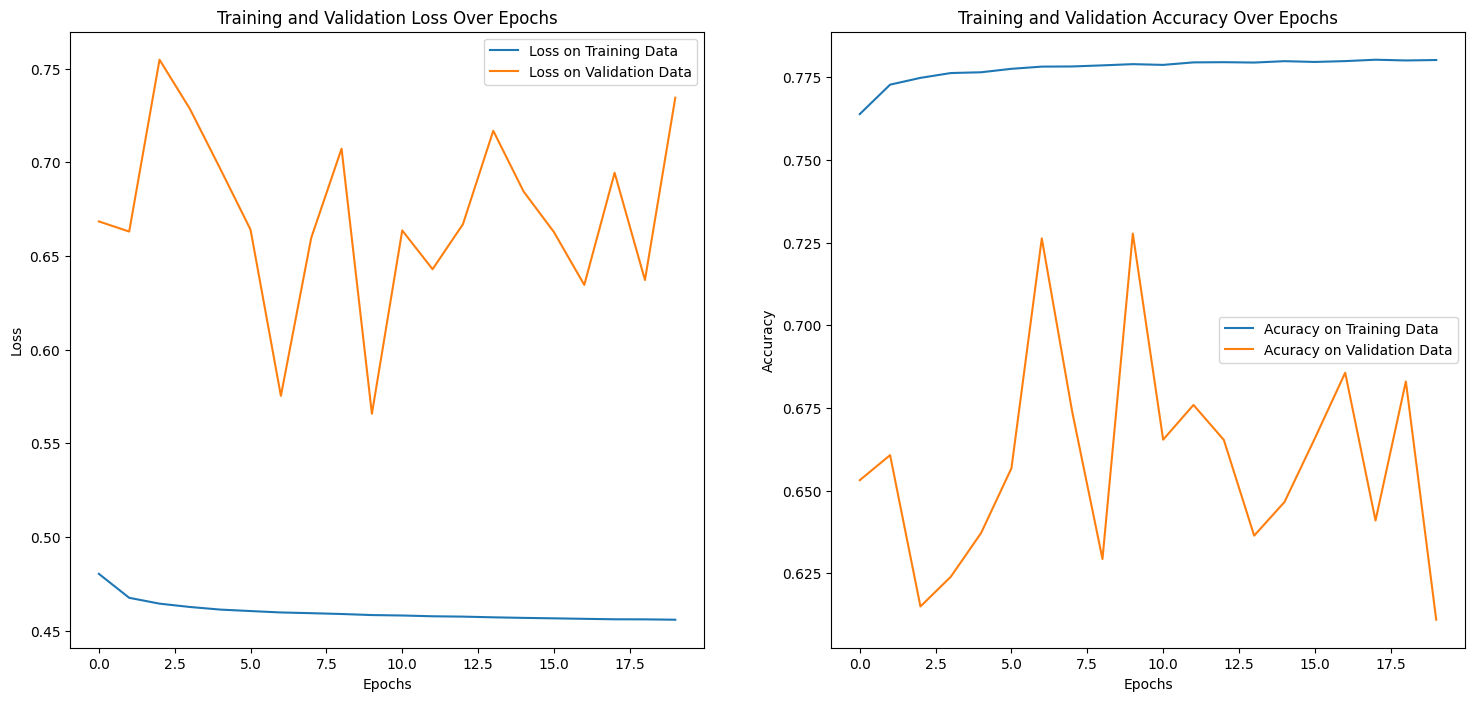

In [ ]:
#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [ ]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 33s 2ms/step
Classe prédite       0      1
Classe réelle                
0               376052  54377
1                42800  68086
              precision    recall  f1-score   support

           0       0.90      0.87      0.89    430429
           1       0.56      0.61      0.58    110886

    accuracy                           0.82    541315
   macro avg       0.73      0.74      0.73    541315
weighted avg       0.83      0.82      0.82    541315



# DNN02
relu activation

In [ ]:
inputs = Input(shape = 92, name = "Input")

dense1 = Dense(units = 32, activation = "relu", kernel_initializer ='normal', name = "Dense_1") #activation changed
dense2 = Dense(units = 1, activation = "sigmoid", kernel_initializer ='normal', name = "Dense_2") #activation changed

x=dense1(inputs)
outputs=dense2(x)

model = Model(inputs = inputs, outputs = outputs)

model.compile(loss = "binary_crossentropy",
              optimizer = "adam",
              metrics = ["accuracy"])

DNN02=model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'),epochs=20,batch_size=32,validation_split=0.2)

Epoch 1/20
12937/12937 [==============================] - 32s 2ms/step - loss: 0.4798 - accuracy: 0.7644 - val_loss: 0.6155 - val_accuracy: 0.6997
Epoch 2/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4666 - accuracy: 0.7737 - val_loss: 0.6708 - val_accuracy: 0.6542
Epoch 3/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4640 - accuracy: 0.7756 - val_loss: 0.6561 - val_accuracy: 0.6660
Epoch 4/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4625 - accuracy: 0.7762 - val_loss: 0.6249 - val_accuracy: 0.6858
Epoch 5/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4614 - accuracy: 0.7771 - val_loss: 0.6567 - val_accuracy: 0.6701
Epoch 6/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4604 - accuracy: 0.7775 - val_loss: 0.7105 - val_accuracy: 0.6355
Epoch 7/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4597 - accuracy: 0.7780 - val_loss: 0

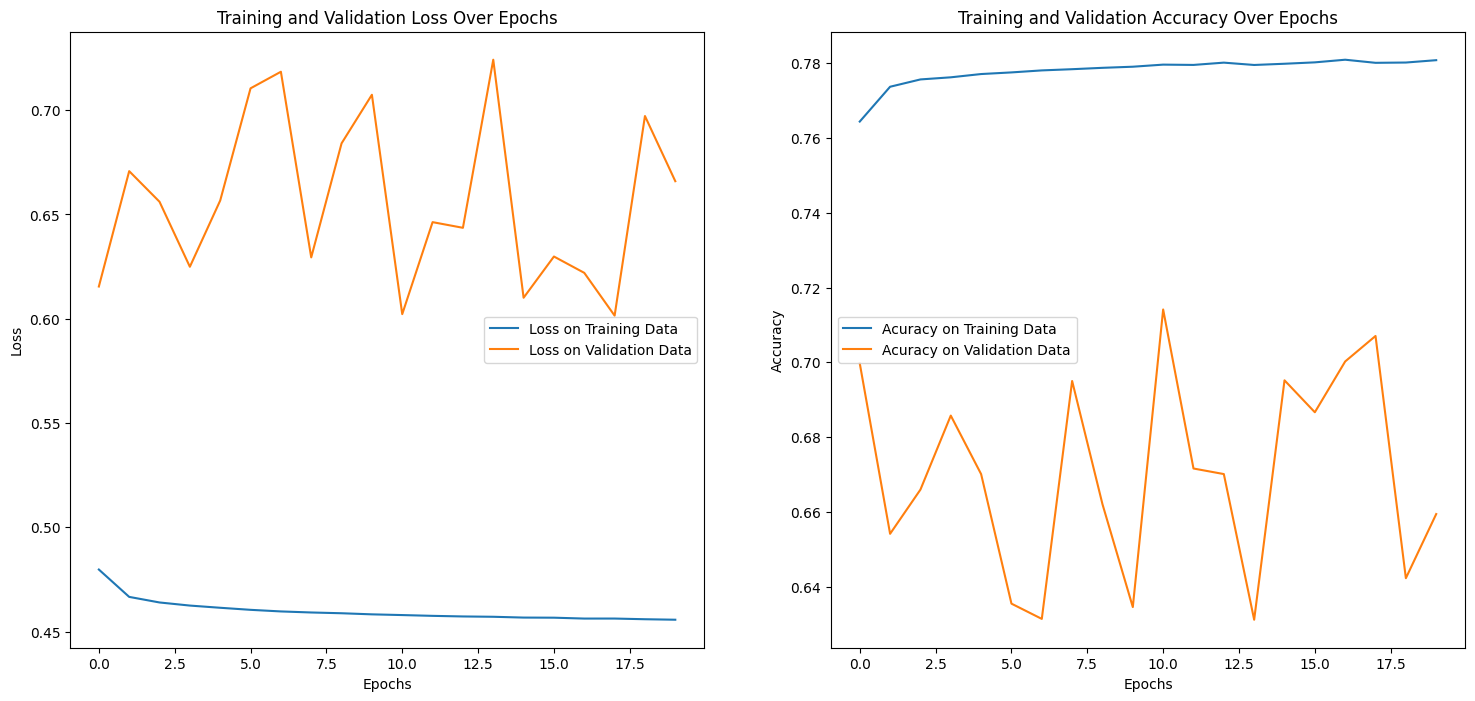

In [ ]:
dnn=DNN02

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [ ]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 38s 2ms/step
Classe prédite       0      1
Classe réelle                
0               365661  64768
1                37695  73191
              precision    recall  f1-score   support

           0       0.91      0.85      0.88    430429
           1       0.53      0.66      0.59    110886

    accuracy                           0.81    541315
   macro avg       0.72      0.75      0.73    541315
weighted avg       0.83      0.81      0.82    541315



# DNN03 callbacks

In [ ]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]

inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='normal', name="Dense_1")
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='normal', name="Dense_2")

dense1 = dense1(inputs)
outputs = dense2(dense1)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN04 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 40s 3ms/step - loss: 0.4806 - accuracy: 0.7641 - val_loss: 0.6351 - val_accuracy: 0.6763 - lr: 0.0010
Epoch 2/20
   94/12937 [..............................] - ETA: 21s - loss: 0.4643 - accuracy: 0.7806

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 28s 2ms/step - loss: 0.4685 - accuracy: 0.7725 - val_loss: 0.6252 - val_accuracy: 0.6843 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4653 - accuracy: 0.7746 - val_loss: 0.6362 - val_accuracy: 0.6794 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4635 - accuracy: 0.7755 - val_loss: 0.7061 - val_accuracy: 0.6416 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4623 - accuracy: 0.7767 - val_loss: 0.6495 - val_accuracy: 0.6807 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4584 - accuracy: 0.7787 - val_loss: 0.6591 - val_accuracy: 0.6692 - lr: 1.0000e-04
Epoch 7/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4579 - accuracy: 0.7795 - val_loss: 0.6524 - val_accuracy: 0.6728 - lr: 1.0000e-04


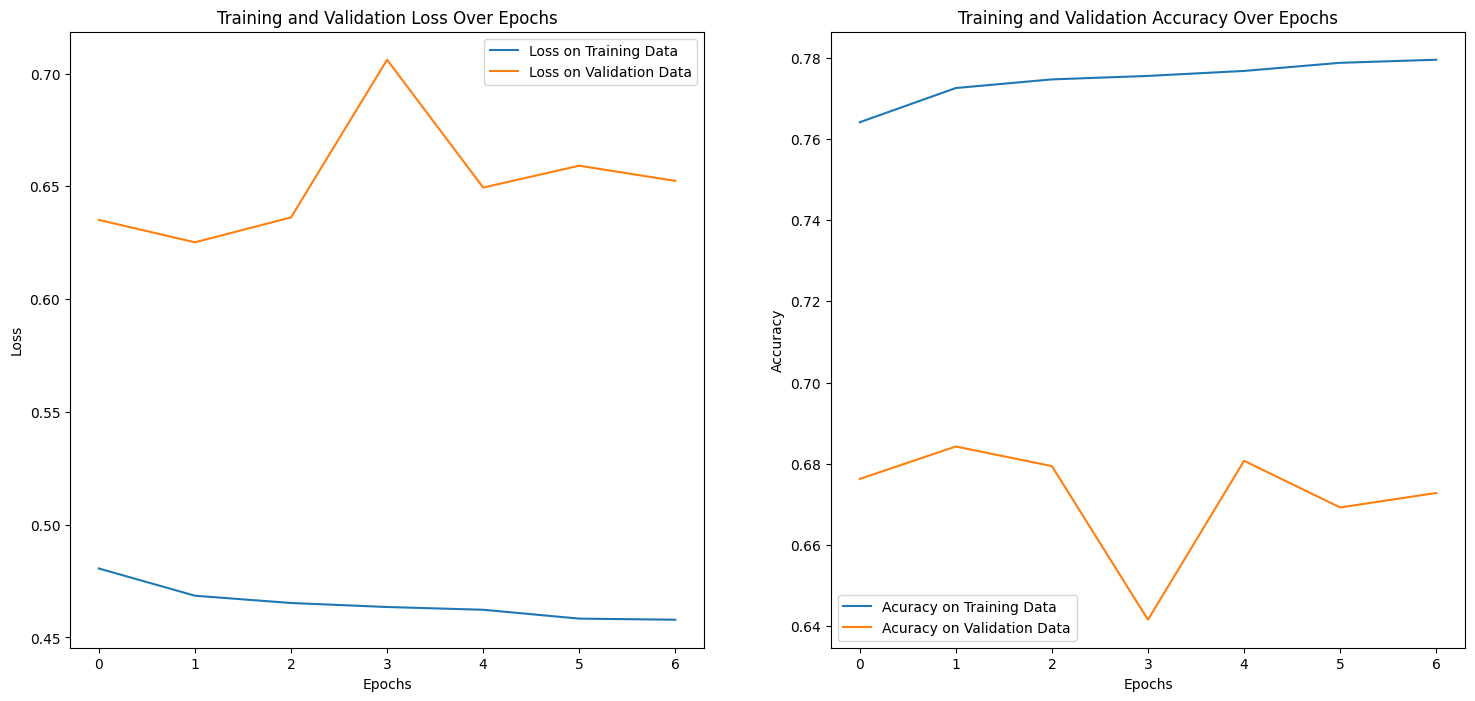

In [ ]:
dnn=DNN03

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [ ]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               361442  68987
1                36158  74728
              precision    recall  f1-score   support

           0       0.91      0.84      0.87    430429
           1       0.52      0.67      0.59    110886

    accuracy                           0.81    541315
   macro avg       0.71      0.76      0.73    541315
weighted avg       0.83      0.81      0.81    541315



# DNN04 re-test later
kernel_initializer=glorot_normal/he_normal/lecun_normal better for relu

In [ ]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1") #kernel_init changed
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2") #kernel_init changed

dense1 = dense1(inputs)
outputs = dense2(dense1)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN04 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 31s 2ms/step - loss: 0.4815 - accuracy: 0.7642 - val_loss: 0.6763 - val_accuracy: 0.6480 - lr: 0.0010
Epoch 2/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4690 - accuracy: 0.7717 - val_loss: 0.7380 - val_accuracy: 0.6205 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 28s 2ms/step - loss: 0.4657 - accuracy: 0.7744 - val_loss: 0.5540 - val_accuracy: 0.7399 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 27s 2ms/step - loss: 0.4639 - accuracy: 0.7753 - val_loss: 0.5638 - val_accuracy: 0.7276 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4626 - accuracy: 0.7759 - val_loss: 0.6627 - val_accuracy: 0.6677 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4617 - accuracy: 0.7768 - val_loss: 0.7008 - val_accuracy: 0.6289 - lr: 0.0010
Epoch 7/20
12937/12937 [================

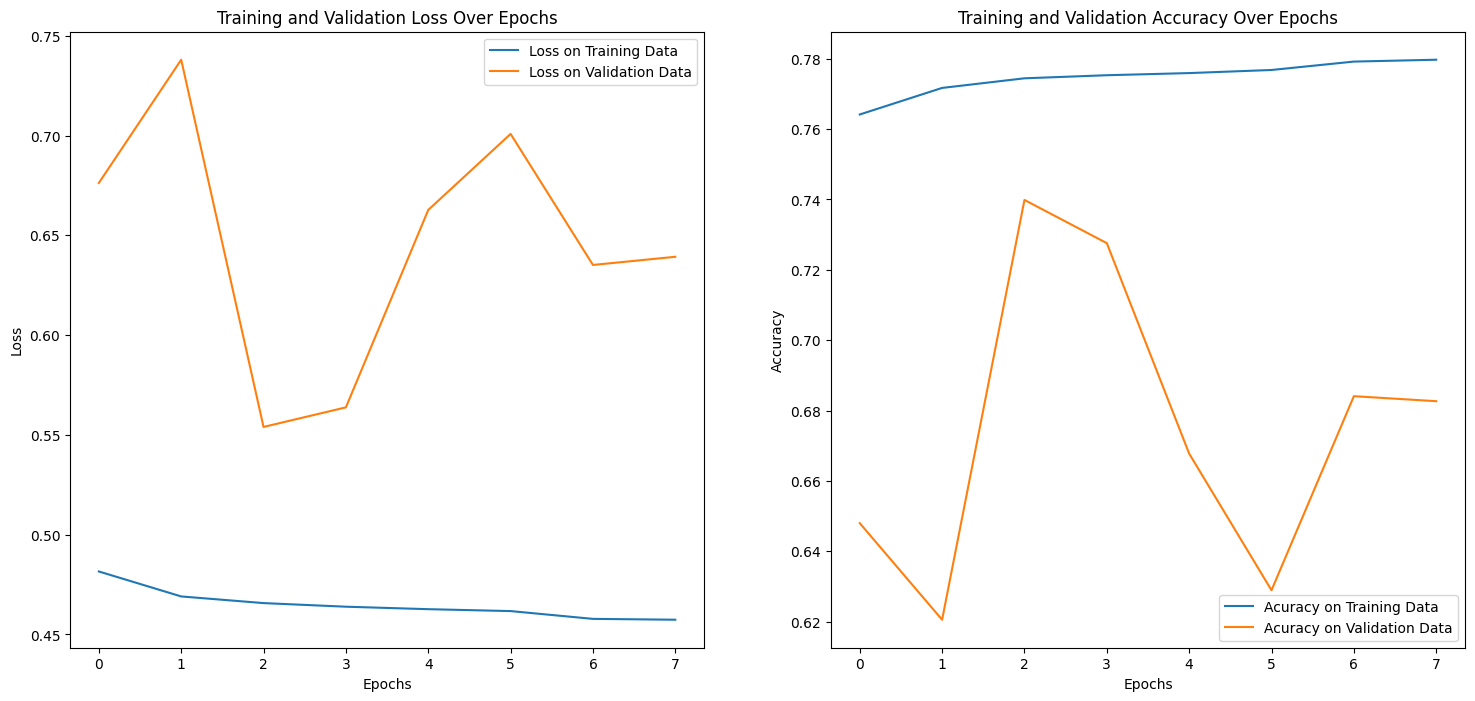

In [ ]:
dnn=DNN04

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [ ]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               358834  71595
1                35141  75745
              precision    recall  f1-score   support

           0       0.91      0.83      0.87    430429
           1       0.51      0.68      0.59    110886

    accuracy                           0.80    541315
   macro avg       0.71      0.76      0.73    541315
weighted avg       0.83      0.80      0.81    541315



# DNN05 ✅
Dropout: technique de régularisation efficace pour les DNN car elle aide à prévenir le surapprentissage en réduisant la dépendance excessive aux données d'entraînement, améliorant ainsi la capacité du modèle à généraliser sur de nouvelles données

In [8]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer = Dropout(0.5) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2")

dense1 = dense1(inputs)
dropout=dropout_layer(dense1) #dropout layer
outputs = dense2(dropout)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN05 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.5119 - accuracy: 0.7516 - val_loss: 0.7155 - val_accuracy: 0.5804 - lr: 0.0010
Epoch 2/20
   37/12937 [..............................] - ETA: 38s - loss: 0.4734 - accuracy: 0.7796 

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 28s 2ms/step - loss: 0.4912 - accuracy: 0.7609 - val_loss: 0.6717 - val_accuracy: 0.6334 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 24s 2ms/step - loss: 0.4891 - accuracy: 0.7622 - val_loss: 0.7133 - val_accuracy: 0.6140 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 18s 1ms/step - loss: 0.4872 - accuracy: 0.7634 - val_loss: 0.6918 - val_accuracy: 0.6355 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 19s 1ms/step - loss: 0.4870 - accuracy: 0.7641 - val_loss: 0.6431 - val_accuracy: 0.6703 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 18s 1ms/step - loss: 0.4858 - accuracy: 0.7653 - val_loss: 0.6879 - val_accuracy: 0.6430 - lr: 0.0010
Epoch 7/20
12937/12937 [==============================] - 21s 2ms/step - loss: 0.4853 - accuracy: 0.7652 - val_loss: 0.6849 - val_accuracy: 0.6482 - lr: 0.0010
Epoch 8/20
12937/12937 [===========================

In [9]:
dump(DNN05, '/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN05.joblib')
# DNN05 = load('/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN05.joblib')

['/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN05.joblib']

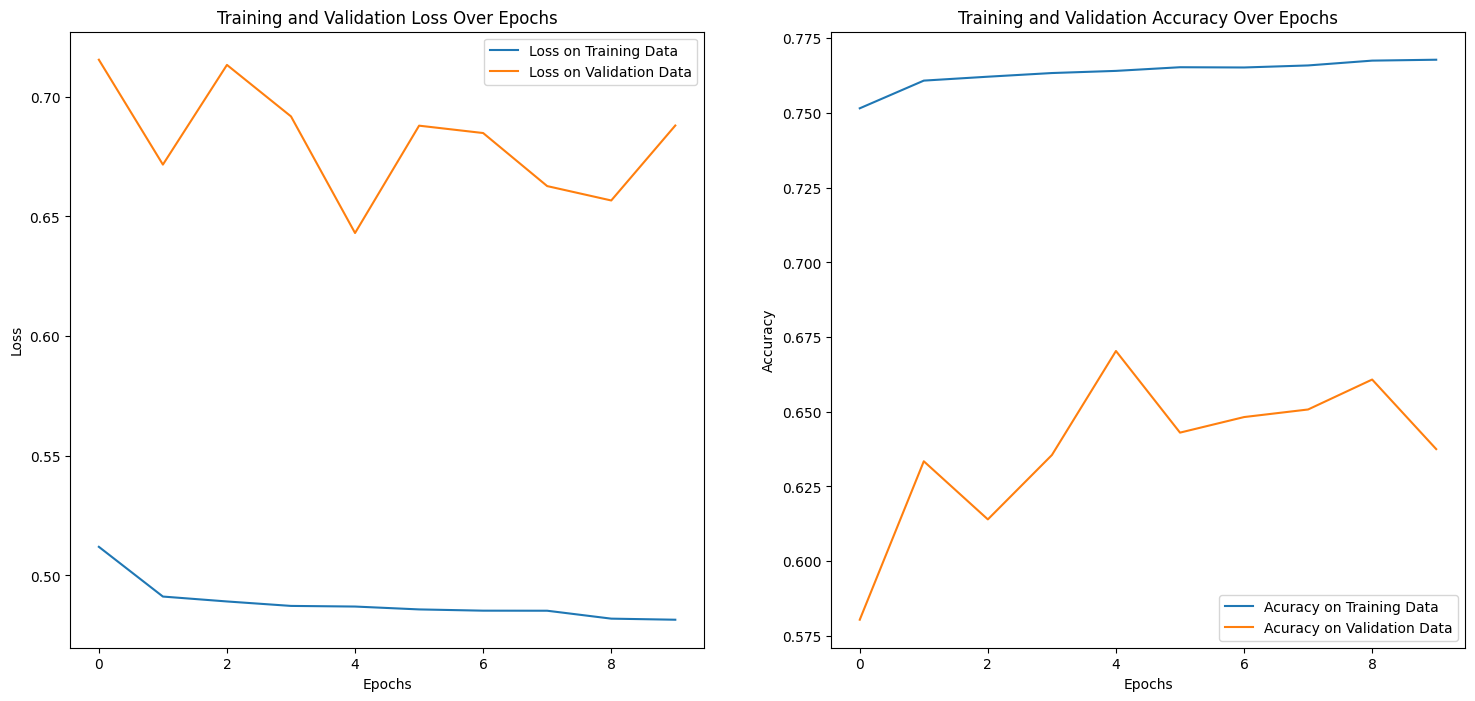

In [10]:
dnn=DNN05

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [11]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 15s 870us/step
Classe prédite       0      1
Classe réelle                
0               368122  62307
1                40273  70613
              precision    recall  f1-score   support

           0       0.90      0.86      0.88    430429
           1       0.53      0.64      0.58    110886

    accuracy                           0.81    541315
   macro avg       0.72      0.75      0.73    541315
weighted avg       0.83      0.81      0.82    541315



# DNN06 more layers

In [ ]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer1 = Dropout(0.5) #dropout layer
dense2 = Dense(units=16, activation="relu", kernel_initializer='glorot_normal', name="Dense_2")
dropout_layer2 = Dropout(0.5) #dropout layer
dense3 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_3")

dense1 = dense1(inputs)
dropout1=dropout_layer1(dense1) #dropout layer
dense2=dense2(dropout1) #new layer
dropout2=dropout_layer2(dense2) #dropout layer
outputs = dense3(dropout2)



model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN06 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 32s 2ms/step - loss: 0.5378 - accuracy: 0.7263 - val_loss: 0.7575 - val_accuracy: 0.5624 - lr: 0.0010
Epoch 2/20
   57/12937 [..............................] - ETA: 35s - loss: 0.5243 - accuracy: 0.7336

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 32s 2ms/step - loss: 0.5123 - accuracy: 0.7462 - val_loss: 0.6651 - val_accuracy: 0.6410 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 32s 3ms/step - loss: 0.5096 - accuracy: 0.7511 - val_loss: 0.7311 - val_accuracy: 0.5707 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 32s 3ms/step - loss: 0.5077 - accuracy: 0.7530 - val_loss: 0.6764 - val_accuracy: 0.6377 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 33s 3ms/step - loss: 0.5072 - accuracy: 0.7546 - val_loss: 0.6985 - val_accuracy: 0.5940 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 32s 2ms/step - loss: 0.5035 - accuracy: 0.7577 - val_loss: 0.6940 - val_accuracy: 0.6127 - lr: 1.0000e-04
Epoch 7/20
12937/12937 [==============================] - 33s 3ms/step - loss: 0.5028 - accuracy: 0.7580 - val_loss: 0.6972 - val_accuracy: 0.6001 - lr: 1.0000e-04


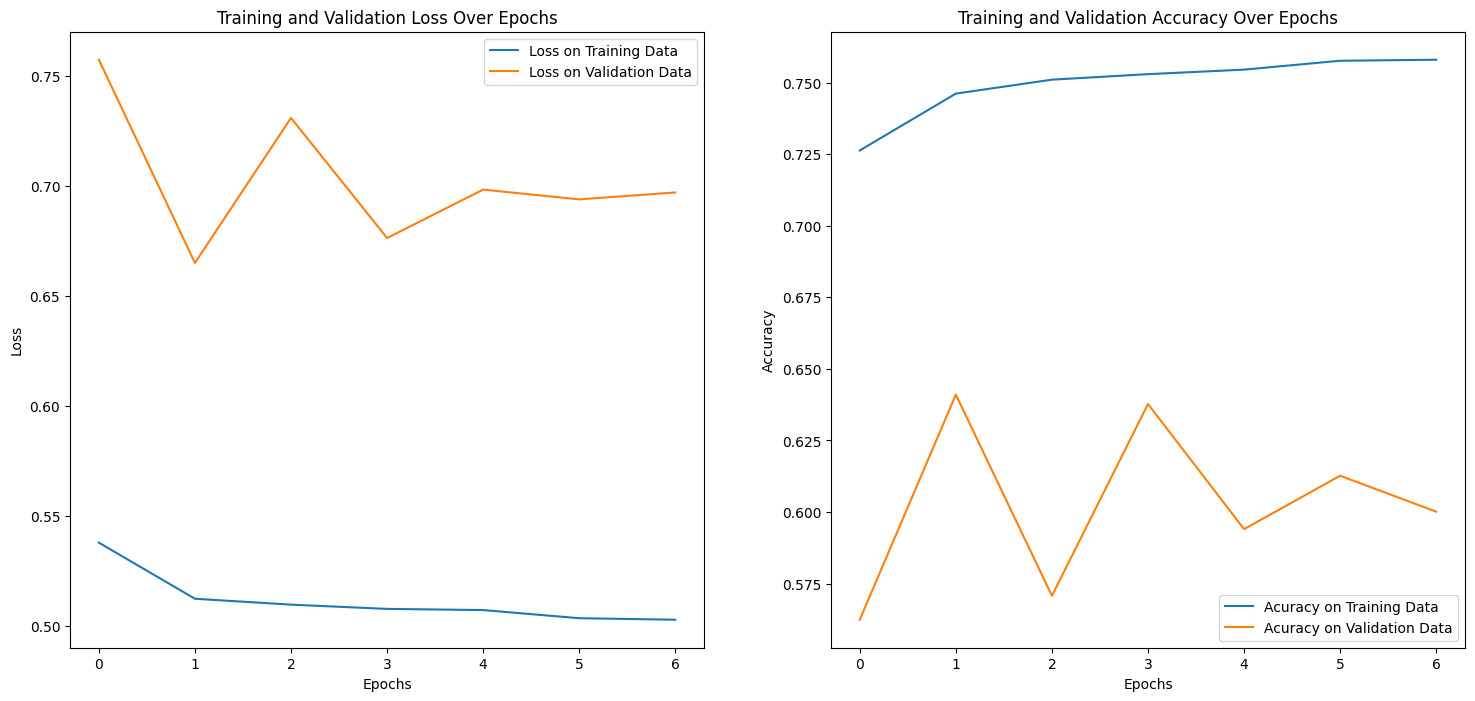

In [ ]:
dnn=DNN06

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [ ]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 24s 1ms/step
Classe prédite       0      1
Classe réelle                
0               373759  56670
1                44286  66600
              precision    recall  f1-score   support

           0       0.89      0.87      0.88    430429
           1       0.54      0.60      0.57    110886

    accuracy                           0.81    541315
   macro avg       0.72      0.73      0.72    541315
weighted avg       0.82      0.81      0.82    541315



#DNN08 even more layers

In [22]:
from keras.regularizers import l1, l2
from sklearn.utils.class_weight import compute_class_weight

callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),  # Sauvegarde du meilleur modèle
    EarlyStopping(patience=5),  # Arrêt de l'entraînement anticipé si la perte de validation ne s'améliore pas pendant 5 époques
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)  # Réduit le taux d'apprentissage si la perte de validation stagne
]


#inputs = Input(shape=92, name="Input")
#dense1 = Dense(units=64, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.01), name="Dense_1")
#dropout_layer1 = Dropout(0.5) #dropout layer
#dense2 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.01), name="Dense_2")
#dropout_layer2 = Dropout(0.5) #dropout layer
#dense3 = Dense(units=16, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.01), name="Dense_3")
#dropout_layer3 = Dropout(0.5) #dropout layer
#dense4 = Dense(units=8, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.01), name="Dense_4")
#dropout_layer4 = Dropout(0.5) #dropout layer
#dense5 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.01), name="Dense_5")

inputs = Input(shape=92, name="Input")
dense1 = Dense(units=64, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer1 = Dropout(0.5) #dropout layer
dense2 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_2")
dropout_layer2 = Dropout(0.5) #dropout layer
dense3 = Dense(units=16, activation="relu", kernel_initializer='glorot_normal', name="Dense_3")
dropout_layer3 = Dropout(0.5) #dropout layer
dense4 = Dense(units=8, activation="relu", kernel_initializer='glorot_normal', name="Dense_4")
dropout_layer4 = Dropout(0.5) #dropout layer
dense5 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_5")

dense1 = dense1(inputs)
dropout1=dropout_layer1(dense1) #dropout layer
dense2=dense2(dropout1) #new layer
dropout2=dropout_layer2(dense2) #dropout layer
dense3=dense3(dropout2) #new layer
dropout3=dropout_layer3(dense3) #dropout layer
dense4=dense4(dropout3) #new layer
dropout4=dropout_layer4(dense4) #dropout layer
outputs = dense5(dropout4)



model = Model(inputs=inputs, outputs=outputs)

# Calcul des poids de classe
class_weights = compute_class_weight(class_weight = "balanced",classes = np.unique(y_train),y = y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}


model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN08 = model.fit(np.asarray(X_train).astype('int'), np.asarray(y_train).astype('int'), epochs=20, \
                  batch_size=32, validation_split=0.2,class_weight=class_weights_dict, callbacks=callbacks)

Epoch 1/20
31577/31577 [==============================] - 109s 3ms/step - loss: 0.5793 - accuracy: 0.6635 - val_loss: 0.4723 - val_accuracy: 0.7566 - lr: 0.0010
Epoch 2/20
   44/31577 [..............................] - ETA: 1:14 - loss: 0.5662 - accuracy: 0.7010

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


31577/31577 [==============================] - 105s 3ms/step - loss: 0.5473 - accuracy: 0.7217 - val_loss: 0.4567 - val_accuracy: 0.7865 - lr: 0.0010
Epoch 3/20
31577/31577 [==============================] - 102s 3ms/step - loss: 0.5449 - accuracy: 0.7263 - val_loss: 0.4741 - val_accuracy: 0.7727 - lr: 0.0010
Epoch 4/20
31577/31577 [==============================] - 104s 3ms/step - loss: 0.5432 - accuracy: 0.7295 - val_loss: 0.5159 - val_accuracy: 0.7471 - lr: 0.0010
Epoch 5/20
31577/31577 [==============================] - 104s 3ms/step - loss: 0.5434 - accuracy: 0.7277 - val_loss: 0.4917 - val_accuracy: 0.7598 - lr: 0.0010
Epoch 6/20
31577/31577 [==============================] - 95s 3ms/step - loss: 0.5360 - accuracy: 0.7355 - val_loss: 0.4950 - val_accuracy: 0.7726 - lr: 1.0000e-04
Epoch 7/20
31577/31577 [==============================] - 105s 3ms/step - loss: 0.5347 - accuracy: 0.7368 - val_loss: 0.4811 - val_accuracy: 0.7756 - lr: 1.0000e-04


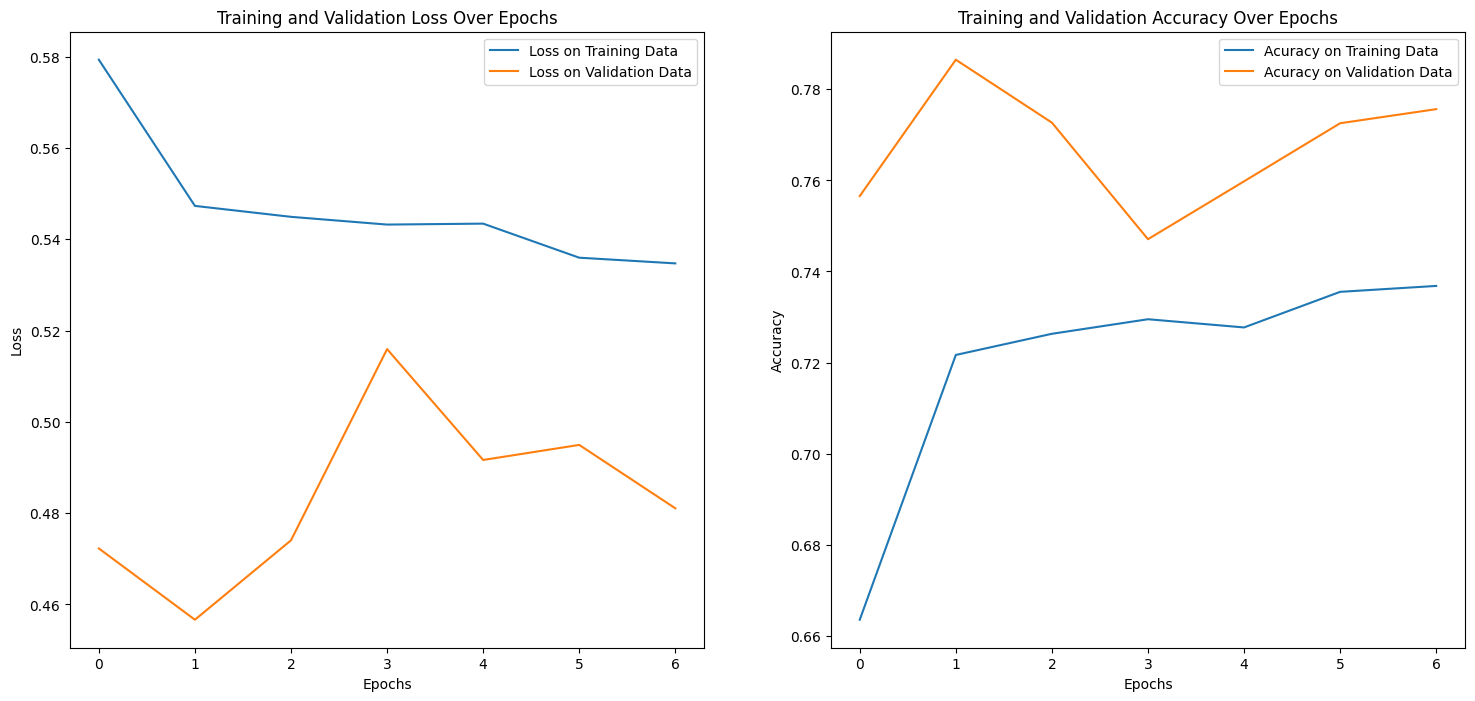

In [23]:
dnn=DNN08

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [24]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 26s 2ms/step
Classe prédite       0      1
Classe réelle                
0               336482  93947
1                27862  83024
              precision    recall  f1-score   support

           0       0.92      0.78      0.85    430429
           1       0.47      0.75      0.58    110886

    accuracy                           0.77    541315
   macro avg       0.70      0.77      0.71    541315
weighted avg       0.83      0.77      0.79    541315



# DNN05b no undersampling

In [10]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer = Dropout(0.5) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2")

dense1 = dense1(inputs)
dropout=dropout_layer(dense1) #dropout layer
outputs = dense2(dropout)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

# Calcul des poids de classe
class_weights = compute_class_weight(class_weight = "balanced",classes = np.unique(y_train),y = y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

DNN05b = model.fit(np.asarray(X_train).astype('int'), np.asarray(y_train).astype('int'),\
                   class_weight=class_weights_dict, epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
31577/31577 [==============================] - 76s 2ms/step - loss: 0.5211 - accuracy: 0.7414 - val_loss: 0.5324 - val_accuracy: 0.7260 - lr: 0.0010
Epoch 2/20
   59/31577 [..............................] - ETA: 1:23 - loss: 0.5055 - accuracy: 0.7500

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


31577/31577 [==============================] - 76s 2ms/step - loss: 0.5079 - accuracy: 0.7447 - val_loss: 0.4969 - val_accuracy: 0.7431 - lr: 0.0010
Epoch 3/20
31577/31577 [==============================] - 73s 2ms/step - loss: 0.5058 - accuracy: 0.7429 - val_loss: 0.5115 - val_accuracy: 0.7370 - lr: 0.0010
Epoch 4/20
31577/31577 [==============================] - 72s 2ms/step - loss: 0.5050 - accuracy: 0.7423 - val_loss: 0.5237 - val_accuracy: 0.7308 - lr: 0.0010
Epoch 5/20
31577/31577 [==============================] - 74s 2ms/step - loss: 0.5042 - accuracy: 0.7437 - val_loss: 0.5154 - val_accuracy: 0.7274 - lr: 0.0010
Epoch 6/20
31577/31577 [==============================] - 72s 2ms/step - loss: 0.5011 - accuracy: 0.7425 - val_loss: 0.4943 - val_accuracy: 0.7479 - lr: 1.0000e-04
Epoch 7/20
31577/31577 [==============================] - 72s 2ms/step - loss: 0.5008 - accuracy: 0.7446 - val_loss: 0.4890 - val_accuracy: 0.7505 - lr: 1.0000e-04
Epoch 8/20
31577/31577 [===================

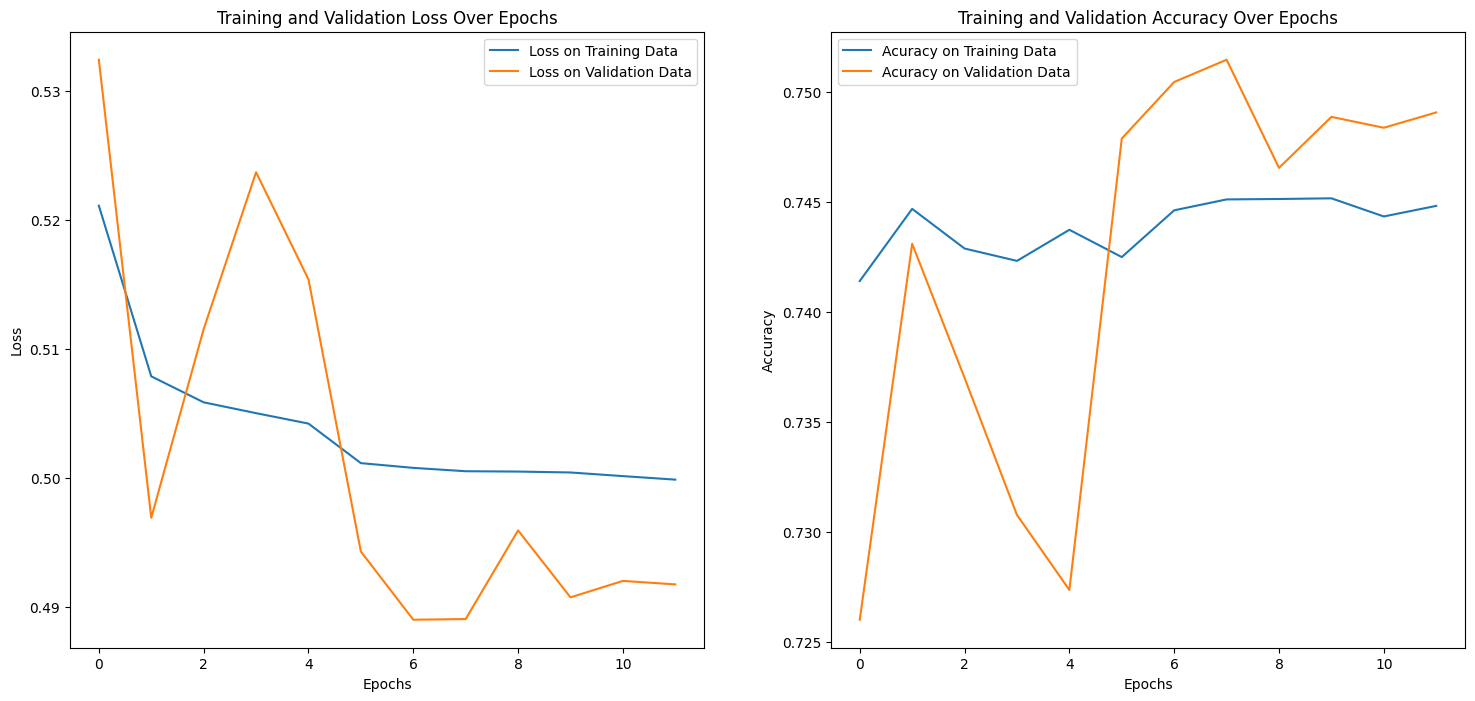

In [11]:
dnn=DNN05b

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [12]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 22s 1ms/step
Classe prédite       0       1
Classe réelle                 
0               317306  113123
1                22574   88312
              precision    recall  f1-score   support

           0       0.93      0.74      0.82    430429
           1       0.44      0.80      0.57    110886

    accuracy                           0.75    541315
   macro avg       0.69      0.77      0.69    541315
weighted avg       0.83      0.75      0.77    541315



# DNN05c leaky Relu

In [13]:
from tensorflow.keras.layers import LeakyReLU

In [14]:
callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation=LeakyReLU(alpha=0.01), kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer = Dropout(0.5) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2")

dense1 = dense1(inputs)
dropout=dropout_layer(dense1) #dropout layer
outputs = dense2(dropout)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

DNN05c = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 37s 3ms/step - loss: 0.5077 - accuracy: 0.7520 - val_loss: 0.6959 - val_accuracy: 0.6062 - lr: 0.0010
Epoch 2/20
   92/12937 [..............................] - ETA: 21s - loss: 0.4897 - accuracy: 0.7636

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 30s 2ms/step - loss: 0.4877 - accuracy: 0.7625 - val_loss: 0.6221 - val_accuracy: 0.6784 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4845 - accuracy: 0.7654 - val_loss: 0.6203 - val_accuracy: 0.6870 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4831 - accuracy: 0.7662 - val_loss: 0.6500 - val_accuracy: 0.6511 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 30s 2ms/step - loss: 0.4818 - accuracy: 0.7669 - val_loss: 0.7013 - val_accuracy: 0.6103 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 29s 2ms/step - loss: 0.4813 - accuracy: 0.7672 - val_loss: 0.6973 - val_accuracy: 0.6222 - lr: 0.0010
Epoch 7/20
12937/12937 [==============================] - 31s 2ms/step - loss: 0.4783 - accuracy: 0.7689 - val_loss: 0.6858 - val_accuracy: 0.6356 - lr: 1.0000e-04
Epoch 8/20
12937/12937 [=======================

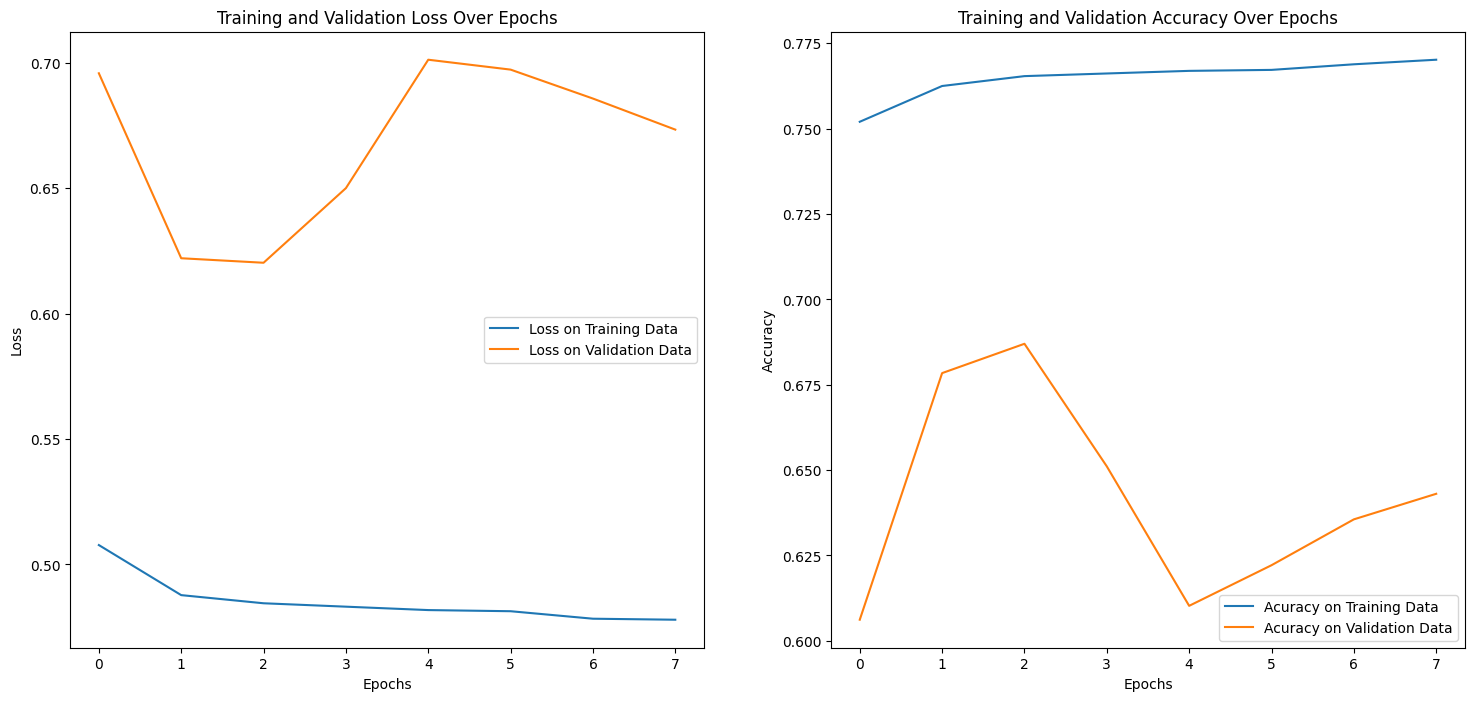

In [15]:
dnn=DNN05c

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [16]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 23s 1ms/step
Classe prédite       0      1
Classe réelle                
0               366543  63886
1                39362  71524
              precision    recall  f1-score   support

           0       0.90      0.85      0.88    430429
           1       0.53      0.65      0.58    110886

    accuracy                           0.81    541315
   macro avg       0.72      0.75      0.73    541315
weighted avg       0.83      0.81      0.82    541315



#DNN09 CONV

In [8]:
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.models import Model

callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]

# Définissez votre modèle convolutionnel
inputs = Input(shape=(92, 1), name="Input")  # Les données d'entrée sont bidimensionnelles (92, 1)

# Ajoutez une couche de convolution
conv1 = Conv1D(32, 3, activation="relu", kernel_initializer="glorot_normal", name="Conv1")(inputs)

# Ajoutez une couche de pooling
pool1 = MaxPooling1D(pool_size=2, name="MaxPool1")(conv1)

# Ajoutez une couche de convolution
conv2 = Conv1D(64, 3, activation="relu", kernel_initializer="glorot_normal", name="Conv2")(pool1)

# Ajoutez une couche de pooling
pool2 = MaxPooling1D(pool_size=2, name="MaxPool2")(conv2)

# Applatissez les données
flatten = Flatten(name="Flatten")(pool2)

# Ajoutez une couche dense
dense1 = Dense(64, activation="relu", kernel_initializer="glorot_normal", name="Dense1")(flatten)

# Ajoutez une couche de dropout
dropout_layer = Dropout(0.5, name="Dropout")(dense1)

# Ajoutez une couche de sortie
outputs = Dense(1, activation="sigmoid", kernel_initializer="glorot_normal", name="Output")(dropout_layer)

# Créez le modèle
conv_model = Model(inputs=inputs, outputs=outputs)

# Compilez le modèle avec la même fonction de perte et le même optimiseur
conv_model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

# Entraînez le modèle avec vos données
DNN09= conv_model.fit(
    np.expand_dims(np.asarray(X_ru).astype('int'), axis=-1),  # Ajoutez une dimension pour indiquer un canal (1)
    np.asarray(y_ru).astype('int'),
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=callbacks
)


Epoch 1/20
12937/12937 [==============================] - 153s 12ms/step - loss: 0.5231 - accuracy: 0.7424 - val_loss: 0.7135 - val_accuracy: 0.6185 - lr: 0.0010
Epoch 2/20
   13/12937 [..............................] - ETA: 1:57 - loss: 0.5250 - accuracy: 0.7380

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 153s 12ms/step - loss: 0.5017 - accuracy: 0.7558 - val_loss: 0.6847 - val_accuracy: 0.6373 - lr: 0.0010
Epoch 3/20
12937/12937 [==============================] - 153s 12ms/step - loss: 0.4947 - accuracy: 0.7594 - val_loss: 0.5389 - val_accuracy: 0.7483 - lr: 0.0010
Epoch 4/20
12937/12937 [==============================] - 149s 12ms/step - loss: 0.4927 - accuracy: 0.7613 - val_loss: 0.6506 - val_accuracy: 0.6510 - lr: 0.0010
Epoch 5/20
12937/12937 [==============================] - 153s 12ms/step - loss: 0.4900 - accuracy: 0.7622 - val_loss: 0.6543 - val_accuracy: 0.6518 - lr: 0.0010
Epoch 6/20
12937/12937 [==============================] - 152s 12ms/step - loss: 0.4894 - accuracy: 0.7628 - val_loss: 0.6459 - val_accuracy: 0.6652 - lr: 0.0010
Epoch 7/20
12937/12937 [==============================] - 150s 12ms/step - loss: 0.4829 - accuracy: 0.7668 - val_loss: 0.6597 - val_accuracy: 0.6509 - lr: 1.0000e-04
Epoch 8/20
12937/12937 [===========

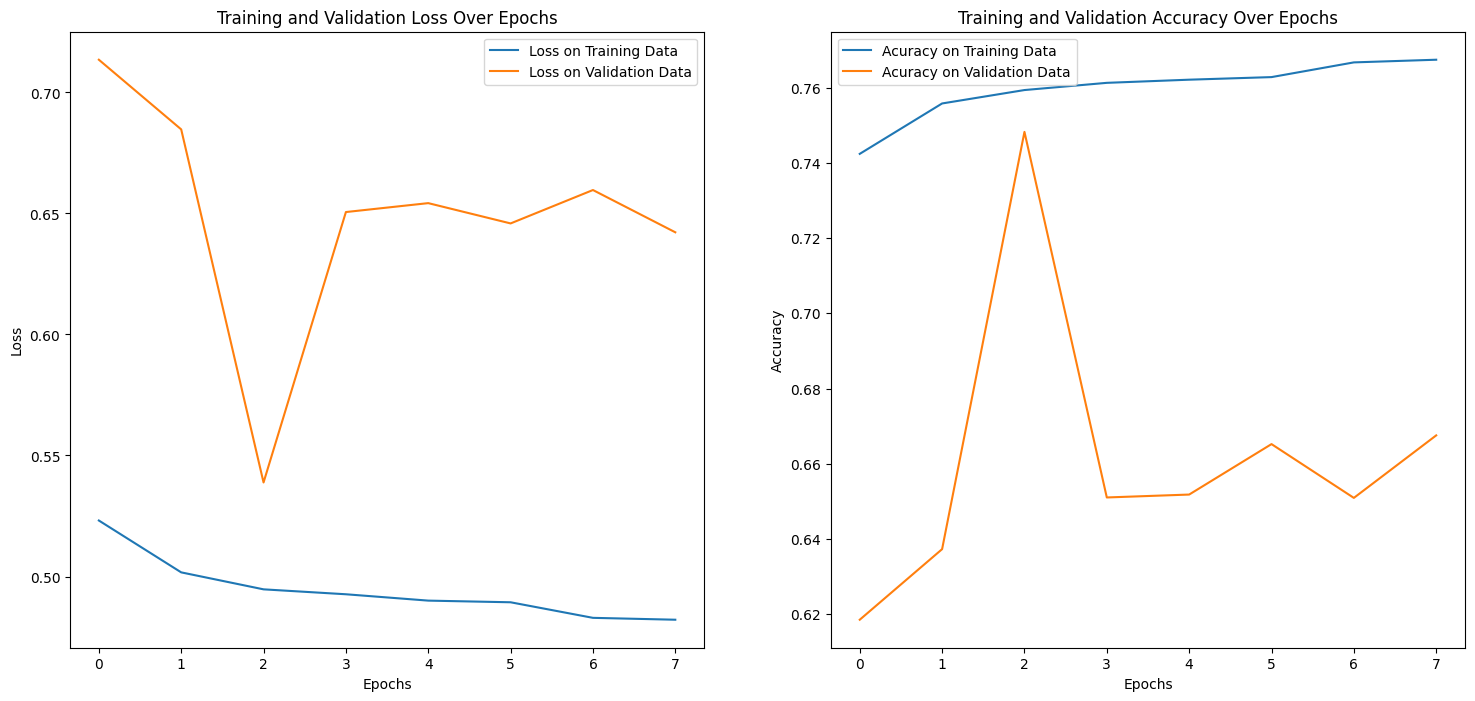

In [9]:
dnn=DNN09

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [10]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 63s 4ms/step
Classe prédite       0      1
Classe réelle                
0               359473  70956
1                37064  73822
              precision    recall  f1-score   support

           0       0.91      0.84      0.87    430429
           1       0.51      0.67      0.58    110886

    accuracy                           0.80    541315
   macro avg       0.71      0.75      0.72    541315
weighted avg       0.83      0.80      0.81    541315



#DNN10 Learning rate ✅

In [12]:
import tensorflow as tf

callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer = Dropout(0.5) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2")

dense1 = dense1(inputs)
dropout=dropout_layer(dense1) #dropout layer
outputs = dense2(dropout)

model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer=tf.optimizers.Adam(learning_rate= 0.00001),
              metrics=["accuracy"])


DNN10 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 34s 3ms/step - loss: 1.5685 - accuracy: 0.5527 - val_loss: 0.9764 - val_accuracy: 0.3096 - lr: 1.0000e-05
Epoch 2/20
   96/12937 [..............................] - ETA: 20s - loss: 0.9491 - accuracy: 0.5898

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 22s 2ms/step - loss: 0.7135 - accuracy: 0.6526 - val_loss: 0.7504 - val_accuracy: 0.4923 - lr: 1.0000e-05
Epoch 3/20
12937/12937 [==============================] - 20s 2ms/step - loss: 0.5691 - accuracy: 0.7130 - val_loss: 0.7351 - val_accuracy: 0.5178 - lr: 1.0000e-05
Epoch 4/20
12937/12937 [==============================] - 20s 2ms/step - loss: 0.5447 - accuracy: 0.7285 - val_loss: 0.7355 - val_accuracy: 0.5352 - lr: 1.0000e-05
Epoch 5/20
12937/12937 [==============================] - 22s 2ms/step - loss: 0.5310 - accuracy: 0.7367 - val_loss: 0.7280 - val_accuracy: 0.5565 - lr: 1.0000e-05
Epoch 6/20
12937/12937 [==============================] - 22s 2ms/step - loss: 0.5239 - accuracy: 0.7408 - val_loss: 0.7231 - val_accuracy: 0.5692 - lr: 1.0000e-05
Epoch 7/20
12937/12937 [==============================] - 22s 2ms/step - loss: 0.5178 - accuracy: 0.7446 - val_loss: 0.7101 - val_accuracy: 0.5889 - lr: 1.0000e-05
Epoch 8/20
12937/12937 [===

In [13]:
dump(DNN10, '/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN10.joblib')
# DNN10 = load('/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN10.joblib')

['/content/drive/MyDrive/Colab Notebooks/Models/103_DNN_grav_DNN10.joblib']

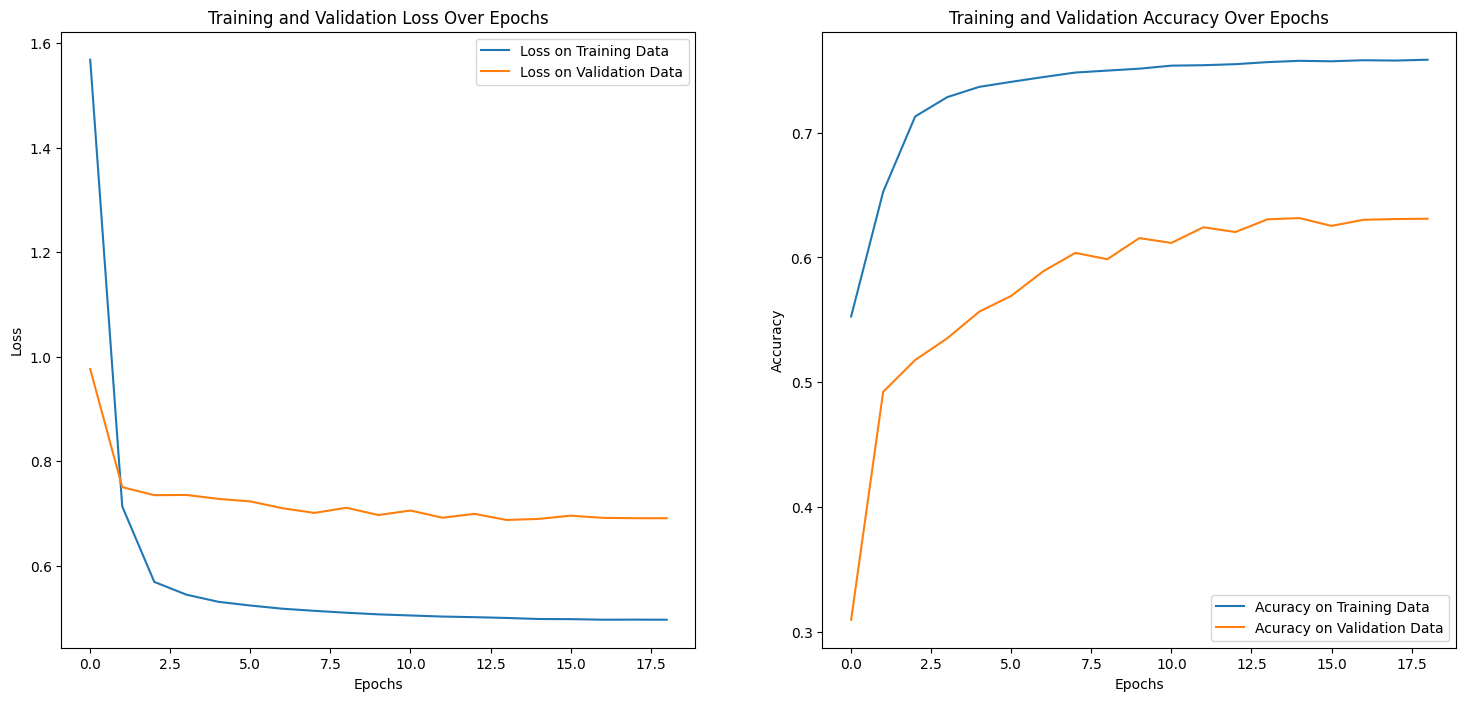

In [14]:
dnn=DNN10

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

In [15]:
y_pred = dnn.model.predict(np.asarray(X_test).astype('float64'))
y_pred_class = [0 if valeur < 0.5 else 1 for valeur in y_pred]

cm = pd.crosstab(y_test, y_pred_class, rownames=['Classe réelle'], colnames=['Classe prédite'])
print(cm)
report = classification_report(y_test, y_pred_class)
print(report)

16917/16917 [==============================] - 17s 978us/step
Classe prédite       0      1
Classe réelle                
0               364199  66230
1                41225  69661
              precision    recall  f1-score   support

           0       0.90      0.85      0.87    430429
           1       0.51      0.63      0.56    110886

    accuracy                           0.80    541315
   macro avg       0.71      0.74      0.72    541315
weighted avg       0.82      0.80      0.81    541315



#DNN11 trying to tackle overfiting ❌

In [9]:
import tensorflow as tf
from tensorflow.keras.regularizers import l2

callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


# inputs = Input(shape=92, name="Input")
# dense1 = Dense(units=64, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.001), name="Dense_1")
# dropout_layer1 = Dropout(0.7) #dropout layer
# dense2 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.001), name="Dense_2")
# dropout_layer2 = Dropout(0.7) #dropout layer
# dense3 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.001), name="Dense_3")

# dense1 = dense1(inputs)
# dropout1=dropout_layer1(dense1) #dropout layer
# dense2 = dense2(dropout1)
# dropout2=dropout_layer2(dense2) #dropout layer
# outputs = dense3(dropout2)


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.001), name="Dense_1")
# dropout_layer1 = Dropout(0.9) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal',kernel_regularizer=l2(0.001), name="Dense_2")

dense1 = dense1(inputs)
# dropout1=dropout_layer1(dense1) #dropout layer
outputs = dense2(dense1)


model = Model(inputs=inputs, outputs=outputs)

model.compile(loss="binary_crossentropy",
              optimizer=tf.optimizers.Adam(learning_rate= 0.00001),
              metrics=["accuracy"])


DNN11 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 22s 2ms/step - loss: 0.8161 - accuracy: 0.6407 - val_loss: 0.8033 - val_accuracy: 0.4804 - lr: 1.0000e-05
Epoch 2/20
  137/12937 [..............................] - ETA: 14s - loss: 0.5638 - accuracy: 0.7438

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 22s 2ms/step - loss: 0.5463 - accuracy: 0.7436 - val_loss: 0.7534 - val_accuracy: 0.5638 - lr: 1.0000e-05
Epoch 3/20
12937/12937 [==============================] - 26s 2ms/step - loss: 0.5231 - accuracy: 0.7536 - val_loss: 0.7257 - val_accuracy: 0.5985 - lr: 1.0000e-05
Epoch 4/20
12937/12937 [==============================] - 22s 2ms/step - loss: 0.5145 - accuracy: 0.7572 - val_loss: 0.7197 - val_accuracy: 0.6084 - lr: 1.0000e-05
Epoch 5/20
12937/12937 [==============================] - 19s 1ms/step - loss: 0.5101 - accuracy: 0.7594 - val_loss: 0.7117 - val_accuracy: 0.6177 - lr: 1.0000e-05
Epoch 6/20
12937/12937 [==============================] - 18s 1ms/step - loss: 0.5074 - accuracy: 0.7607 - val_loss: 0.6887 - val_accuracy: 0.6375 - lr: 1.0000e-05
Epoch 7/20
12937/12937 [==============================] - 21s 2ms/step - loss: 0.5055 - accuracy: 0.7612 - val_loss: 0.7067 - val_accuracy: 0.6231 - lr: 1.0000e-05
Epoch 8/20
12937/12937 [===

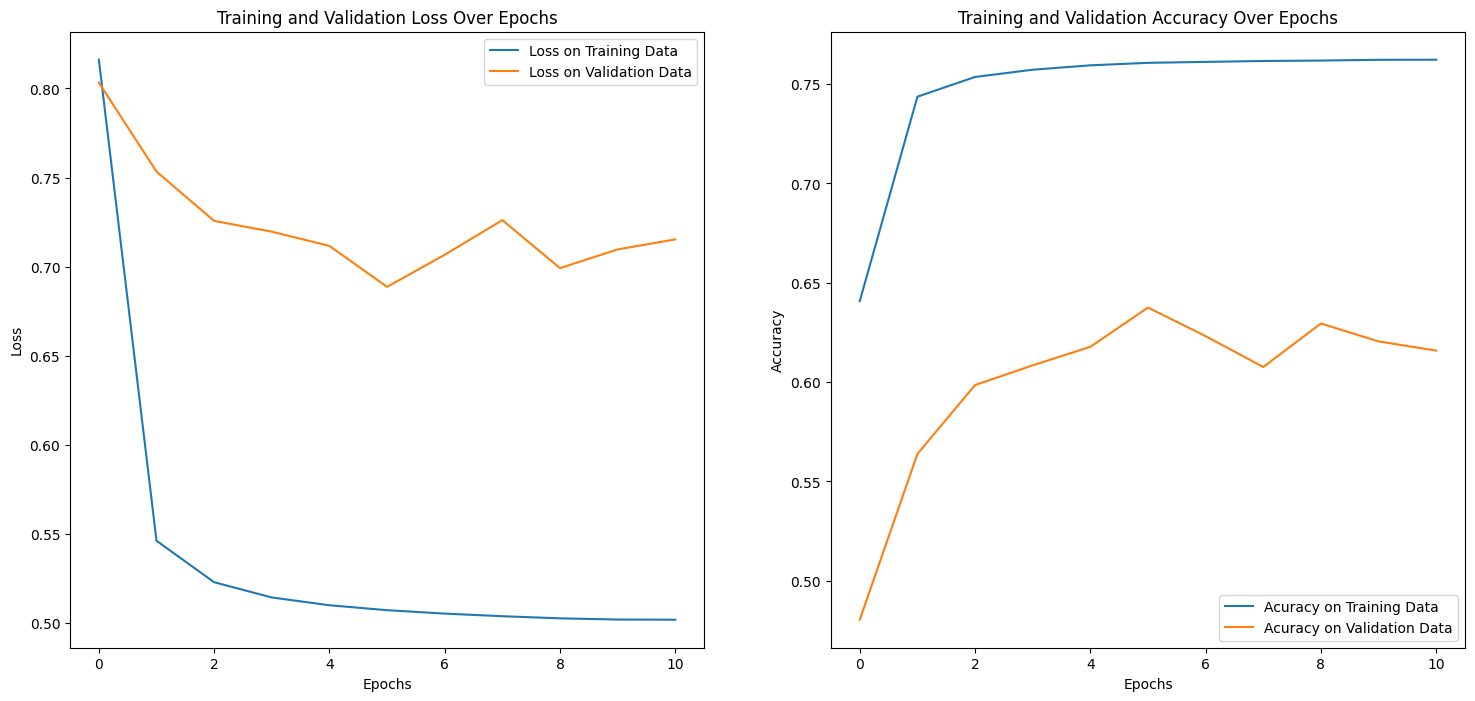

In [10]:
dnn=DNN11

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()

#DNN12 custom loss function

> Bloc en retrait



In [11]:
import tensorflow as tf

callbacks = [
    ModelCheckpoint("model_checkpoint.h5", save_best_only=True),
    EarlyStopping(patience=5),
    ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3, min_lr=1e-6)
]


inputs = Input(shape=92, name="Input")
dense1 = Dense(units=32, activation="relu", kernel_initializer='glorot_normal', name="Dense_1")
dropout_layer = Dropout(0.5) #dropout layer
dense2 = Dense(units=1, activation="sigmoid", kernel_initializer='glorot_normal', name="Dense_2")

dense1 = dense1(inputs)
dropout=dropout_layer(dense1) #dropout layer
outputs = dense2(dropout)

model = Model(inputs=inputs, outputs=outputs)

def custom_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = tf.clip_by_value(y_pred, epsilon, 1 - epsilon)
    y_true = tf.cast(y_true, tf.float32)
    loss = -tf.reduce_mean(y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
    return loss


model.compile(loss=custom_loss,
              optimizer=tf.optimizers.Adam(learning_rate= 0.00001),
              metrics=["accuracy"])


DNN12 = model.fit(np.asarray(X_ru).astype('int'), np.asarray(y_ru).astype('int'), epochs=20, batch_size=32, validation_split=0.2, callbacks=callbacks)

Epoch 1/20
12937/12937 [==============================] - 22s 2ms/step - loss: 0.9991 - accuracy: 0.5575 - val_loss: 0.8985 - val_accuracy: 0.2368 - lr: 1.0000e-05
Epoch 2/20
  134/12937 [..............................] - ETA: 14s - loss: 0.7083 - accuracy: 0.5886

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


12937/12937 [==============================] - 21s 2ms/step - loss: 0.6374 - accuracy: 0.6456 - val_loss: 0.8413 - val_accuracy: 0.2859 - lr: 1.0000e-05
Epoch 3/20
12937/12937 [==============================] - 18s 1ms/step - loss: 0.5816 - accuracy: 0.6920 - val_loss: 0.7999 - val_accuracy: 0.4442 - lr: 1.0000e-05
Epoch 4/20
12937/12937 [==============================] - 21s 2ms/step - loss: 0.5583 - accuracy: 0.7140 - val_loss: 0.7883 - val_accuracy: 0.5017 - lr: 1.0000e-05
Epoch 5/20
12937/12937 [==============================] - 19s 1ms/step - loss: 0.5448 - accuracy: 0.7252 - val_loss: 0.7598 - val_accuracy: 0.5581 - lr: 1.0000e-05
Epoch 6/20
12937/12937 [==============================] - 19s 1ms/step - loss: 0.5351 - accuracy: 0.7327 - val_loss: 0.7437 - val_accuracy: 0.5875 - lr: 1.0000e-05
Epoch 7/20
12937/12937 [==============================] - 19s 1ms/step - loss: 0.5289 - accuracy: 0.7372 - val_loss: 0.7323 - val_accuracy: 0.6049 - lr: 1.0000e-05
Epoch 8/20
12937/12937 [===

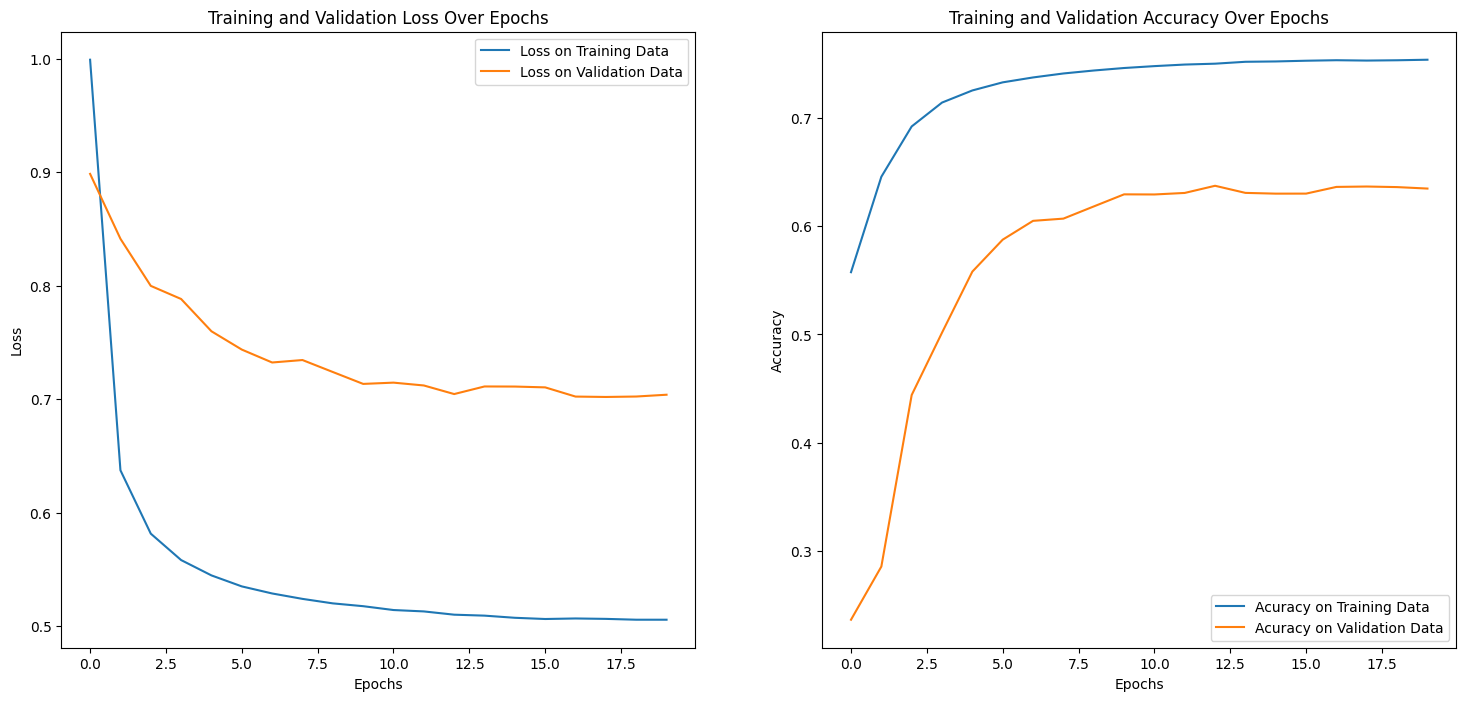

In [12]:
dnn=DNN12

#plot
plt.figure(figsize=(18, 8))

plt.subplot(1,2,1)
plt.plot(dnn.history['loss'], label='Loss on Training Data')
plt.plot(dnn.history['val_loss'], label='Loss on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss Over Epochs')

plt.subplot(1,2,2)
plt.plot(dnn.history['accuracy'], label='Acuracy on Training Data')
plt.plot(dnn.history['val_accuracy'], label='Acuracy on Validation Data')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy Over Epochs')
plt.show()